# Testing the detectability of GAIA black holes with photonic lanterns

In [19]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Importing the necessary modules
from PLsim.otf import OTF
from PLsim.scene import Scene, SceneProjector
from PLsim.system.device import Device
from PLsim.system.lantern import generate_unitary_matrix

import hcipy as hc
import numpy as np
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import pandas as pd
from tqdm import tqdm
import astropy.units as u
import astropy.constants as c

# Custom modules
import functions
from PhotonicLanternDevice import PhotonicLanternDevice
from PhotonicLanternFitting import PhotonicLanternFitting

# Formatting the plots
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Loading Smadar's GAIA BH population data

In [20]:
population_data = pd.read_csv('datafiles/GAIAlikeoutput.txt', delimiter='	')
print(population_data.head())

     a [au]         e  a_old [au]     e_old  m_BH [M_sun]    angle1    angle2  \
0  6.186805  0.814824    16.81608  0.682349     12.635595 -0.466941  2.970442   
1  6.659186  0.960413    16.81608  0.682349     12.635595  1.896240  1.597001   
2  6.161268  0.983240    16.81608  0.682349     12.635595 -0.070061 -0.133664   
3  4.403974  0.926148    16.81608  0.682349     12.635595  2.922422  0.542266   
4  4.665931  0.910985    16.81608  0.682349     12.635595  0.305517 -2.464704   

     angle3    angle4    angle5  
0 -0.600848  100.9770  11.87305  
1  2.038747  100.9822  11.86782  
2  1.541220  100.9848  11.86520  
3 -1.483095  100.9892  11.86079  
4 -1.296062  100.9927  11.85727  


### Plotting Smadar's GAIA BH population data

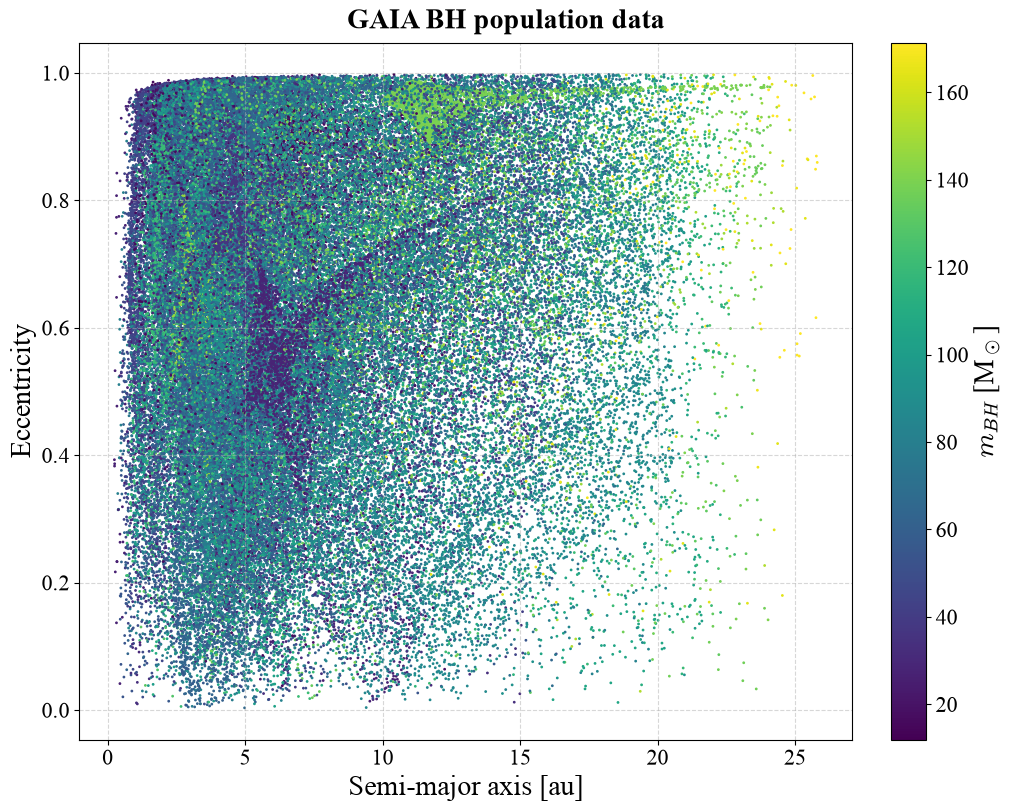

In [21]:
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('GAIA BH population data')

sc = ax.scatter(population_data['a [au]'], population_data['e'], c=population_data['m_BH [M_sun]'], cmap='viridis', label='GAIA BH population', s=1)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label(r'$m_{BH}$ [M$_\odot$]')

ax.set_xlabel('Semi-major axis [au]')
ax.set_ylabel('Eccentricity')

# ax.legend()

ax.grid(True, linestyle='--', alpha=0.5)

plt.show()